In [1]:
# Problem Statement: GenAI-Assisted Network Operations, Root-Cause Analysis & Infrastructure Automation

In [ ]:
# Imagine you are working as a Network Operations (NetOps) Engineer for a large retail organization, such as Walmart.

# The organization has multiple warehouses, distribution centers, network devices, servers and business applications.

# One morning, employees at a distribution center suddenly report:
#     "Our handheld devices are connecting to Wi-Fi, but we cannot access the inventory application. Warehouse operations are getting affected."

# Now, as a network engineer, you need to identify:
# - What exactly has failed?
# - Is it a network connectivity issue, firewall issue, routing problem or application failure?
# - Why did the failure happen?
# - What evidence supports the suspected root cause?
# - How can we safely automate the investigation and prepare a solution?

# The main problem: Traditionally, engineers manually inspect hundreds of logs, alerts, configuration files and monitoring dashboards. This takes time, and identifying the actual root cause can be challenging.

# Our goal is to use Generative AI as an intelligent NetOps assistant to investigate incidents faster, identify probable causes using evidence, and generate safe automation scripts.

### The notebook's central incident is INC-2204, involving distribution center DC-07.

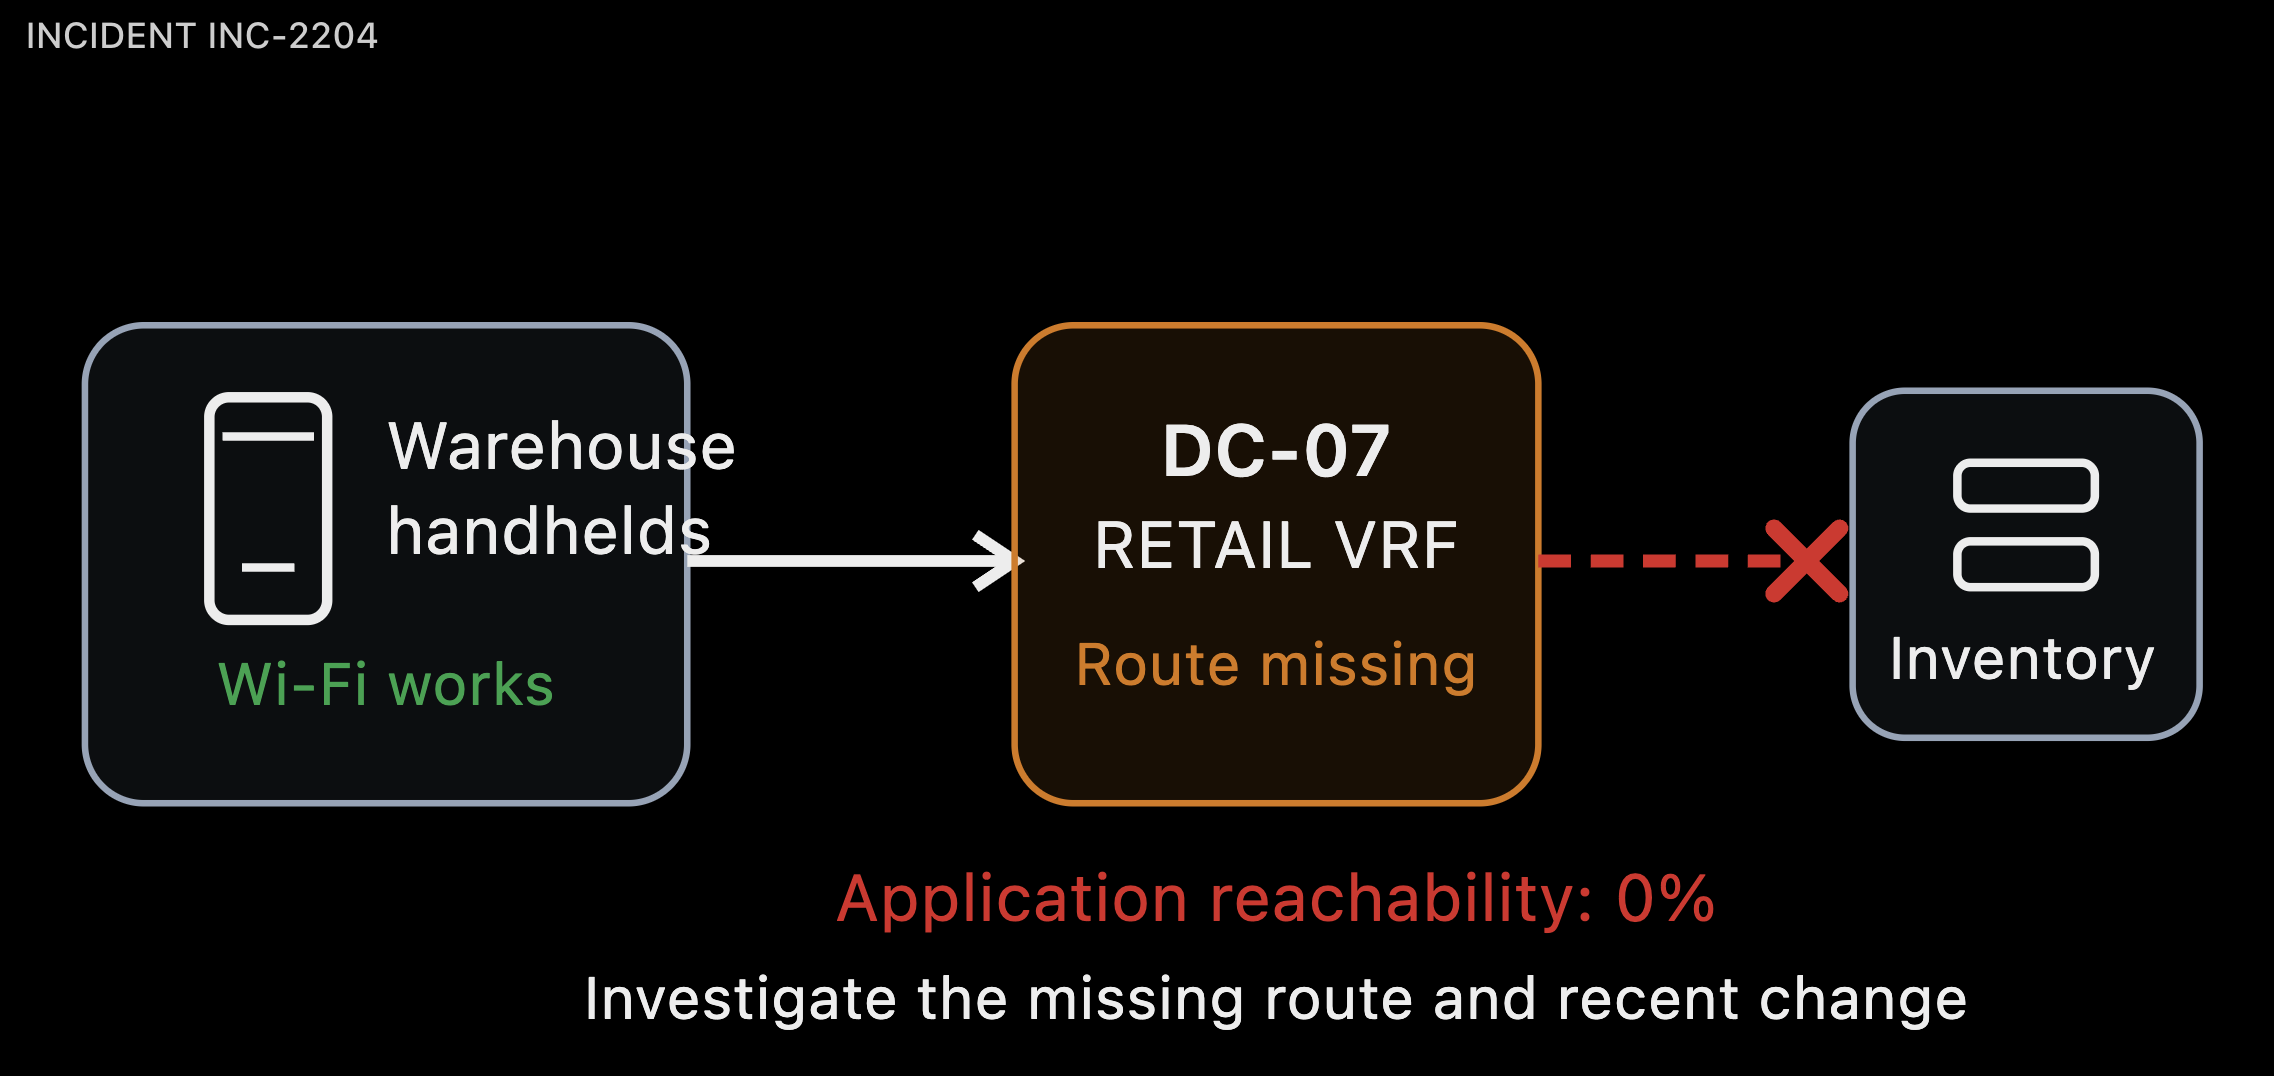

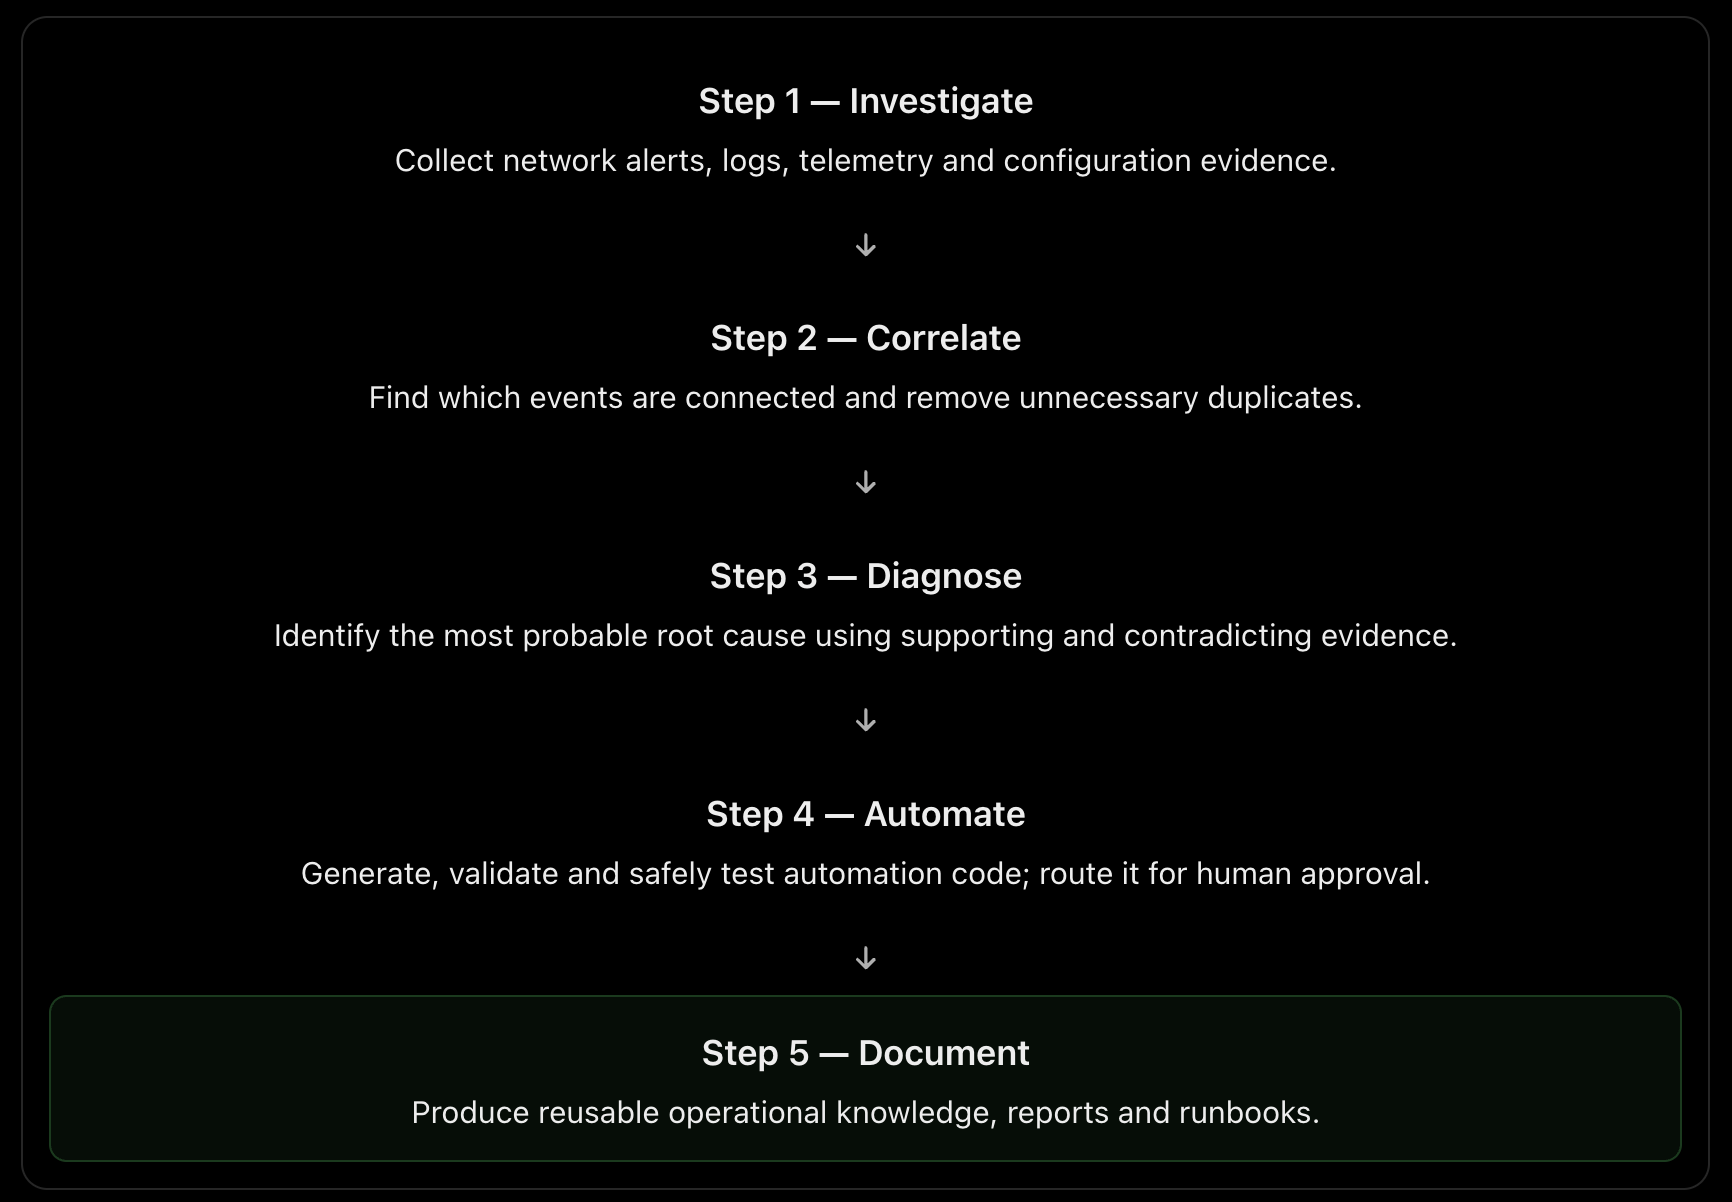

In [3]:
import ast
import io
import json
import os
import warnings
if not os.environ.get("LOKY_MAX_CPU_COUNT"):
    os.environ["LOKY_MAX_CPU_COUNT"] = "1"
warnings.filterwarnings("ignore", message=r"Could not find the number of physical cores.*", category=UserWarning)
import re
import sys
import time
from importlib.metadata import version
from pathlib import Path
from typing import Literal

import hcl2
import pandas as pd
import yaml
from jinja2 import StrictUndefined, Template
from jsonschema import Draft202012Validator
from pydantic import BaseModel, Field
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer

API_KEY_PRESENT = bool(os.getenv("OPENAI_API_KEY"))
LIVE_API = API_KEY_PRESENT and os.getenv("WAL_NET_ENABLE_LIVE_API", "1") == "1"
MODEL = os.getenv("WAL_NET_MODEL", "gpt-5.6-terra")
FAST_MODEL = os.getenv("WAL_NET_FAST_MODEL", "gpt-5.6-luna")
_client = None

def get_client():
    global _client
    if not LIVE_API:
        return None
    if _client is None:
        from openai import OpenAI
        _client = OpenAI()
    return _client

def call_text(
    name: str,
    *,
    instructions: str,
    user_input: str,
    model: str | None = None,
    reasoning_effort: str = "low",
    max_output_tokens: int = 700,
) -> dict | None:
    if not LIVE_API:
        print(f"[{name}] SKIPPED — provide OPENAI_API_KEY for a live response.")
        return None
    started = time.perf_counter()
    response = get_client().responses.create(
        model=model or FAST_MODEL,
        instructions=instructions,
        input=user_input,
        reasoning={"effort": reasoning_effort},
        max_output_tokens=max_output_tokens,
        store=False,
    )
    result = {
        "name": name,
        "model": response.model,
        "latency_seconds": round(time.perf_counter() - started, 3),
        "input_tokens": response.usage.input_tokens if response.usage else None,
        "output_tokens": response.usage.output_tokens if response.usage else None,
        "text": response.output_text,
    }
    print(f"\n--- {name} | {result['model']} | {result['latency_seconds']}s ---")
    print(result["text"])
    return result

def call_structured(
    name: str,
    schema: type[BaseModel],
    *,
    instructions: str,
    user_input: str,
    model: str | None = None,
    reasoning_effort: str = "low",
    show: bool = True,
):
    if not LIVE_API:
        print(f"[{name}] SKIPPED — live Structured Output requires OPENAI_API_KEY.")
        return None
    started = time.perf_counter()
    response = get_client().responses.parse(
        model=model or MODEL,
        instructions=instructions,
        input=user_input,
        reasoning={"effort": reasoning_effort},
        text_format=schema,
        store=False,
    )
    parsed = response.output_parsed
    if parsed is None:
        raise RuntimeError(f"{name}: no parsed output was returned")
    if show:
        print(f"\n--- {name} | {response.model} | {time.perf_counter() - started:.3f}s ---")
        print(parsed.model_dump_json(indent=2))
    return parsed

print("Python:", sys.version.split()[0])
print("Environment:", Path(sys.prefix).name)
print("openai:", version("openai"), "| pydantic:", version("pydantic"))
print("Live API:", LIVE_API, "| Model:", MODEL, "| Fast model:", FAST_MODEL)
if not API_KEY_PRESENT:
    print("NOTE: Live examples will show SKIPPED until OPENAI_API_KEY is configured.")

Python: 3.12.13
Environment: wal_net
openai: 3.3.1 | pydantic: 2.13.4
Live API: True | Model: gpt-5.6-terra | Fast model: gpt-5.6-luna


# Module 1 — AI-Assisted Network & Infrastructure Troubleshooting

## 1.1 Failure domains and the role of GenAI

| Failure domain | Typical symptoms | Evidence an engineer needs | Useful GenAI contribution | Boundary |
|---|---|---|---|---|
| Connectivity failures | Timeout, unreachable service, failed session | Source/destination, path, interface state, reachability tests | Normalize symptoms and propose layer-by-layer checks | Never equate “timeout” with one cause |
| Routing and interface issues | Missing prefix, adjacency reset, interface errors | RIB/FIB, neighbor state, counters, optics, topology | Relate interface events to routing impact and rank tests | Timing alone does not prove causality |
| DNS/DHCP problems | Lookup timeout, wrong answer, lease failure | Resolver/relay health, scopes, ACLs, client configuration | Separate naming/addressing failures from application symptoms | Do not invent server health or lease state |
| Latency and packet loss | Slow transaction, jitter, retransmission | Baselines, hop/path measurements, queue and interface telemetry | Compare scope and time windows; summarize anomalies | Averages can hide tail latency and burst loss |
| Firewall/connectivity problems | Denied flow, reset, asymmetric connection | Policy, hit counters, flow logs, NAT state, approved intent | Explain rules, connect counters to affected flows | A matching rule is not automatically the cause |
| Configuration inconsistencies | Site-specific drift, missing parameter, unexpected behavior | Intended state, running state, version, recent change | Compare configurations and explain the material difference | Generated syntax must be independently validated |
| Infrastructure availability issues | Service or device unavailable, dependency cascade | Health checks, dependency graph, redundancy state, maintenance | Summarize blast radius and competing dependency failures | Do not claim recovery without post-action evidence |

### AI-assisted troubleshooting workflow

**Scope incident → collect trusted evidence → normalize → generate hypotheses → identify contradictions → choose read-only checks → update confidence → recommend → human validation**

GenAI is most valuable in the language-and-reasoning layer. Authoritative operational tools remain the source of current state.

In [4]:
class EvidenceClaim(BaseModel):
    statement: str
    evidence_ids: list[str] = Field(min_length=1)

class TriageHypothesis(BaseModel):
    cause: str
    confidence: Literal["low", "medium", "high"]
    supporting_evidence: list[str]
    missing_evidence: list[str]
    next_read_only_check: str

class TriageCase(BaseModel):
    incident_id: str
    primary_domain: Literal[
        "connectivity", "routing_interface", "dns_dhcp", "latency_loss",
        "firewall", "configuration", "availability"
    ]
    symptoms: list[EvidenceClaim]
    hypotheses: list[TriageHypothesis]
    immediate_escalation: bool

class TriageBatch(BaseModel):
    cases: list[TriageCase]

FAILURE_DOMAIN_CASES = """
CASE INC-101 | E1: Checkout clients in SITE-101 time out to payment-gateway.internal; E2: gateway health is not supplied.
CASE INC-102 | E1: DC-02 edge interface xe-0/0/7 flapped; E2: BGP neighbor reset eight seconds later; E3: optic peer data missing.
CASE INC-103 | E1: SITE-207 clients receive no DHCP lease; E2: relay counters increase; E3: scope utilization unavailable.
CASE INC-104 | E1: Voice-picking p95 latency rose from 80 ms to 610 ms; E2: average WAN loss is 0.2%; E3: queue telemetry missing.
CASE INC-105 | E1: Firewall deny counter increases for client-to-resolver UDP/53; E2: rule intent not supplied.
CASE INC-106 | E1: RETAIL VRF at DC-07 lacks prefix 10.90.40.0/24; E2: route-target differs from intended template.
CASE INC-107 | E1: Inventory API is unhealthy in one region; E2: database and network dependency health are not supplied.
""".strip()

In [6]:
# We ask Generative AI to examine each incident, identify the type of network problem, suggest possible root causes, and recommend safe troubleshooting steps.

# Define the expected problem category for each incident
EXPECTED_DOMAIN_BY_INCIDENT = {
    "INC-101": "connectivity",
    "INC-102": "routing_interface",
    "INC-103": "dns_dhcp",
    "INC-104": "latency_loss",
    "INC-105": "firewall",
    "INC-106": "configuration",
    "INC-107": "availability",
}

# Define what evidence GenAI is allowed to use for each incident
ALLOWED_TRIAGE_EVIDENCE = {
    "INC-101": {"E1", "E2"},
    "INC-102": {"E1", "E2", "E3"},
    "INC-103": {"E1", "E2", "E3"},
    "INC-104": {"E1", "E2", "E3"},
    "INC-105": {"E1", "E2"},
    "INC-106": {"E1", "E2"},
    "INC-107": {"E1", "E2"},
}

# Function to correct AI classifications
# This function accepts a collection of AI-generated incident analyses (TriageBatch).

# It returns two things:
# 1. The incident collection with corrected categories.
# 2. A list recording the corrections made.
def normalize_known_training_domains(batch: TriageBatch) -> tuple[TriageBatch, list[str]]:
    """Apply the exercise's declared taxonomy; record rather than hide model corrections."""
    corrections = [] # Records where AI classifications were changed.
    normalized = [] # Stores all incident cases after normalization.
    for case in batch.cases:
        expected = EXPECTED_DOMAIN_BY_INCIDENT.get(case.incident_id)
        if expected and case.primary_domain != expected:
            corrections.append(f"{case.incident_id}: {case.primary_domain} -> {expected}")
            case = case.model_copy(update={"primary_domain": expected}) # INC-105: connectivity -> firewall
        normalized.append(case)
    return batch.model_copy(update={"cases": normalized}), corrections

# Function to validate the AI-generated incident analysis
def validate_triage_batch(batch: TriageBatch) -> list[str]:
    problems = []
    # Check 1 — Are all seven incidents present?
    expected_ids = set(EXPECTED_DOMAIN_BY_INCIDENT)
    actual_ids = [case.incident_id for case in batch.cases]
    if set(actual_ids) != expected_ids or len(actual_ids) != len(expected_ids):
        problems.append(f"Expected each canonical incident exactly once; received {actual_ids}")

    # Check 2 — Is the incident category correct?
    for case in batch.cases:
        expected_domain = EXPECTED_DOMAIN_BY_INCIDENT.get(case.incident_id)
        if expected_domain is None:
            problems.append(f"Unknown incident ID: {case.incident_id}")
            continue
        if case.primary_domain != expected_domain:
            problems.append(
                f"{case.incident_id} must map to {expected_domain}, not {case.primary_domain}"
            )
        
        # Check 3 — Has GenAI provided a possible root cause?
        if not case.hypotheses:
            problems.append(f"{case.incident_id} has no hypothesis")
        # Check 4 — Collect all evidence cited by GenAI
        cited = set()
        for symptom in case.symptoms:
            cited.update(symptom.evidence_ids)
        for hypothesis in case.hypotheses:
            cited.update(hypothesis.supporting_evidence)
            if not hypothesis.next_read_only_check.strip():
                problems.append(f"{case.incident_id} has no next read-only check")
        unknown = cited - ALLOWED_TRIAGE_EVIDENCE[case.incident_id]
        if unknown:
            problems.append(f"{case.incident_id} cites unsupported evidence: {sorted(unknown)}")
    return sorted(set(problems))

triage_batch = call_structured(
    "Module 1 — seven-domain AI-assisted triage",
    TriageBatch,
    model=FAST_MODEL,
    instructions=(
        "Triage every case using only its evidence IDs. The canonical training taxonomy is: "
        "INC-101=connectivity, INC-102=routing_interface, INC-103=dns_dhcp, "
        "INC-104=latency_loss, INC-105=firewall, INC-106=configuration, "
        "INC-107=availability. Return every incident exactly once. Do not invent command results, "
        "configuration, server health, or confirmed causes. Give concise hypotheses and the smallest "
        "useful read-only check."
    ),
    user_input=FAILURE_DOMAIN_CASES,
    show=False,
)

accepted_triage_batch = None
triage_problems = ["Live triage was not generated."]
if triage_batch:
    triage_batch, domain_corrections = normalize_known_training_domains(triage_batch)
    if domain_corrections:
        print("CONTROLLED TAXONOMY CORRECTIONS:")
        for correction in domain_corrections:
            print("-", correction)
    triage_problems = validate_triage_batch(triage_batch)
    print("TRIAGE RELEASE:", "PASS" if not triage_problems else "REJECT")
    for problem in triage_problems:
        print("-", problem)
    if not triage_problems:
        accepted_triage_batch = triage_batch
        print(accepted_triage_batch.model_dump_json(indent=2))
        triage_rows = []
        for case in accepted_triage_batch.cases:
            triage_rows.append({
                "incident_id": case.incident_id,
                "domain": case.primary_domain,
                "top_hypothesis": case.hypotheses[0].cause,
                "confidence": case.hypotheses[0].confidence,
                "next_check": case.hypotheses[0].next_read_only_check,
            })
        display(pd.DataFrame(triage_rows))
else:
    print("TRIAGE RELEASE: SKIPPED — no live response is available.")

TRIAGE RELEASE: PASS
{
  "cases": [
    {
      "incident_id": "INC-101",
      "primary_domain": "connectivity",
      "symptoms": [
        {
          "statement": "Checkout clients in SITE-101 time out when connecting to payment-gateway.internal.",
          "evidence_ids": [
            "E1"
          ]
        },
        {
          "statement": "Payment gateway health information is unavailable.",
          "evidence_ids": [
            "E2"
          ]
        }
      ],
      "hypotheses": [
        {
          "cause": "A connectivity failure exists between SITE-101 checkout clients and payment-gateway.internal; endpoint health is unconfirmed.",
          "confidence": "medium",
          "supporting_evidence": [
            "E1"
          ],
          "missing_evidence": [
            "E2"
          ],
          "next_read_only_check": "Compare DNS resolution and TCP reachability to the gateway from an affected client and a known-good site."
        }
      ],
      "immedia

,incident_id,domain,top_hypothesis,confidence,next_check
0,INC-101,connectivity,A connectivity failure exists between SITE-101...,medium,Compare DNS resolution and TCP reachability to...
1,INC-102,routing_interface,The interface flap may have caused the subsequ...,high,"Review interface flap, error, optical-power, a..."
2,INC-103,dns_dhcp,DHCP requests are reaching or traversing the r...,medium,Inspect relay forward/reply counters and read-...
3,INC-104,latency_loss,A latency or queuing condition is affecting vo...,medium,"Review time-correlated interface utilization, ..."
4,INC-105,firewall,A firewall policy is denying client DNS traffi...,high,Identify the matching deny rule and compare it...
5,INC-106,configuration,A route-target configuration mismatch may be p...,high,Compare the VRF import/export route-targets an...
6,INC-107,availability,A regional Inventory API availability issue ex...,high,Check regional API health indicators and read-...


# Module 2 — Intelligent Log, Alert & Event Analysis

## 2.1 From event volume to engineering meaning

| Capability | What it does | Engineering value | Common failure mode |
|---|---|---|---|
| Log summarization | Compresses repeated messages while preserving material facts | Faster situational awareness | Drops timestamps, scope or negative evidence |
| Alert enrichment | Adds service, site, severity, owner and evidence context | Makes an alert actionable | Enrichment source is stale or unauthorized |
| Event correlation | Groups events by time, topology, service and shared change | Reveals a candidate incident chain | Treats temporal proximity as causation |
| Alert-noise reduction | Deduplicates and suppresses known non-actionable repeats | Reduces cognitive load | Hides a symptom that changed severity or scope |
| Incident clustering | Groups semantically or operationally related events | Finds incident candidates across sources | Similar wording creates a false cluster |
| Timeline reconstruction | Orders evidence and marks clock/source gaps | Supports causal reasoning and handoffs | Mixed time zones or delayed ingestion distort order |
| Engineering narrative | Converts events into a concise, evidence-linked account | Improves war-room alignment | Produces a persuasive story with unsupported links |

Use deterministic filtering for exact duplicate IDs, maintenance windows and explicit suppression rules. Use GenAI after this first reduction to summarize, enrich and reason over the retained evidence.

In [8]:
pd.set_option("display.max_colwidth", 100)

In [9]:
EVENTS = [
    {"id":"EV1","time":"09:41:58","site":"DC-07","source":"alert","severity":"critical","text":"Inventory VIP reachability from RETAIL VRF dropped to 0%."},
    {"id":"EV2","time":"09:41:59","site":"DC-07","source":"alert","severity":"critical","text":"Inventory VIP reachability from RETAIL VRF dropped to 0%."},
    {"id":"EV3","time":"09:42:04","site":"DC-07","source":"ticket","severity":"high","text":"Picking handhelds authenticate but cannot open inventory application."},
    {"id":"EV4","time":"09:42:12","site":"DC-07","source":"routing","severity":"high","text":"Prefix 10.90.40.0/24 absent from RETAIL VRF; BGP sessions established."},
    {"id":"EV5","time":"09:42:18","site":"DC-07","source":"telemetry","severity":"info","text":"WAN RTT 22 ms and packet loss 0.1%, within baseline."},
    {"id":"EV6","time":"09:42:26","site":"DC-07","source":"change","severity":"warning","text":"CHG-204 completed at 09:36; VRF import policy changed."},
    {"id":"EV7","time":"09:43:00","site":"SITE-114","source":"alert","severity":"warning","text":"Guest Wi-Fi client count exceeded forecast; service healthy."},
    {"id":"EV8","time":"09:43:05","site":"DC-07","source":"firewall","severity":"info","text":"Policy simulation permits handheld subnet to inventory VIP."},
]

events_df = pd.DataFrame(EVENTS).sort_values("time")
display(events_df)

,id,time,site,source,severity,text
0,EV1,09:41:58,DC-07,alert,critical,Inventory VIP reachability from RETAIL VRF dropped to 0%.
1,EV2,09:41:59,DC-07,alert,critical,Inventory VIP reachability from RETAIL VRF dropped to 0%.
2,EV3,09:42:04,DC-07,ticket,high,Picking handhelds authenticate but cannot open inventory application.
3,EV4,09:42:12,DC-07,routing,high,Prefix 10.90.40.0/24 absent from RETAIL VRF; BGP sessions established.
4,EV5,09:42:18,DC-07,telemetry,info,"WAN RTT 22 ms and packet loss 0.1%, within baseline."
5,EV6,09:42:26,DC-07,change,warning,CHG-204 completed at 09:36; VRF import policy changed.
6,EV7,09:43:00,SITE-114,alert,warning,Guest Wi-Fi client count exceeded forecast; service healthy.
7,EV8,09:43:05,DC-07,firewall,info,Policy simulation permits handheld subnet to inventory VIP.


In [ ]:
# Exact duplicate reduction is deterministic; semantic clustering is an analytical aid.
# Remove duplicate events
deduped = events_df.drop_duplicates(subset=["site", "source", "text"], keep="first").copy()

# Convert log messages into numerical features
vectorizer = TfidfVectorizer(stop_words="english")
event_vectors = vectorizer.fit_transform(deduped["text"])
cluster_count = min(3, len(deduped))
deduped["cluster"] = KMeans(n_clusters=cluster_count, random_state=42, n_init=10).fit_predict(event_vectors)

print(f"Raw events: {len(events_df)} | After exact deduplication: {len(deduped)}")
display(deduped[["id", "time", "site", "source", "severity", "cluster", "text"]])

Raw events: 8 | After exact deduplication: 7


,id,time,site,source,severity,cluster,text
0,EV1,09:41:58,DC-07,alert,critical,0,Inventory VIP reachability from RETAIL VRF dropped to 0%.
2,EV3,09:42:04,DC-07,ticket,high,0,Picking handhelds authenticate but cannot open inventory application.
3,EV4,09:42:12,DC-07,routing,high,0,Prefix 10.90.40.0/24 absent from RETAIL VRF; BGP sessions established.
4,EV5,09:42:18,DC-07,telemetry,info,1,"WAN RTT 22 ms and packet loss 0.1%, within baseline."
5,EV6,09:42:26,DC-07,change,warning,0,CHG-204 completed at 09:36; VRF import policy changed.
6,EV7,09:43:00,SITE-114,alert,warning,2,Guest Wi-Fi client count exceeded forecast; service healthy.
7,EV8,09:43:05,DC-07,firewall,info,0,Policy simulation permits handheld subnet to inventory VIP.


In [11]:
class EnrichedAlert(BaseModel):
    event_id: str
    normalized_symptom: str
    affected_scope: str
    related_evidence_ids: list[str]
    missing_context: list[str]

class CorrelationGroup(BaseModel):
    group_name: str
    evidence_ids: list[str]
    relationship: str
    causal_status: Literal["not_assessed", "correlated", "causally_supported"]

class NarrativeEvent(BaseModel):
    time: str
    description: str
    evidence_ids: list[str]

class EventIntelligenceReport(BaseModel):
    summary: str
    enriched_alerts: list[EnrichedAlert]
    noise_candidates: list[str]
    correlation_groups: list[CorrelationGroup]
    incident_clusters: list[list[str]]
    timeline: list[NarrativeEvent]
    engineering_narrative: str
    unknowns: list[str]

In [12]:
# Convert events into text for GenAI
event_context = "\n".join(
    f"{row.id} | {row.time} | {row.site} | {row.source} | {row.severity} | {row.text}"
    for row in deduped.itertuples(index=False)
)
# Example Output:
# EV1 | 09:41:58 | DC-07 | alert | critical | Inventory VIP reachability from RETAIL VRF dropped to 0%.
# EV4 | 09:42:12 | DC-07 | routing | high | Prefix 10.90.40.0/24 absent from RETAIL VRF; BGP sessions established.
# EV6 | 09:42:26 | DC-07 | change | warning | CHG-204 completed at 09:36; VRF import policy changed.


# Call GenAI to generate an intelligence report
event_intelligence = call_structured(
    "Module 2 — log, alert and event intelligence",
    EventIntelligenceReport,
    instructions=(
        "Transform retained operational events into an evidence-linked engineering account. "
        "Use only supplied event IDs. Keep unrelated sites separate. Correlation is not causation. "
        "Treat normal telemetry and permits as potentially contradicting evidence, not noise."
    ),
    user_input=event_context,
)


--- Module 2 — log, alert and event intelligence | gpt-5.6-terra | 15.800s ---
{
  "summary": "DC-07 experienced an inventory-application reachability incident affecting the RETAIL VRF and picking handheld workflows. The evidence consistently localizes the failure to loss of route prefix 10.90.40.0/24 in the RETAIL VRF while BGP sessions remained established. A VRF import-policy change completed shortly before the incident is temporally correlated, but the retained events do not prove it caused the missing prefix. SITE-114's guest Wi-Fi forecast alert is separate and reports healthy service.",
  "enriched_alerts": [
    {
      "event_id": "EV1",
      "normalized_symptom": "Inventory VIP unreachable from the RETAIL VRF",
      "affected_scope": "DC-07; RETAIL VRF access to the inventory VIP",
      "related_evidence_ids": [
        "EV3",
        "EV4",
        "EV5",
        "EV6",
        "EV8"
      ],
      "missing_context": [
        "Inventory VIP address and its route/prefix 

In [13]:
def validate_event_intelligence(report: EventIntelligenceReport, allowed_ids: set[str]) -> list[str]:
    problems = []
    cited = set()
    for alert in report.enriched_alerts:
        cited.add(alert.event_id)
        cited.update(alert.related_evidence_ids)
    for group in report.correlation_groups:
        cited.update(group.evidence_ids)
        if group.causal_status == "causally_supported" and len(set(group.evidence_ids)) < 2:
            problems.append(f"Causal group lacks converging evidence: {group.group_name}")
    for event in report.timeline:
        cited.update(event.evidence_ids)
    for cluster in report.incident_clusters:
        cited.update(cluster)
    unknown = cited - allowed_ids
    if unknown:
        problems.append(f"Unknown event IDs: {sorted(unknown)}")
    unrelated_noise = [eid for eid in report.noise_candidates if eid not in allowed_ids]
    if unrelated_noise:
        problems.append(f"Noise list contains unknown IDs: {unrelated_noise}")
    return problems

if event_intelligence:
    event_problems = validate_event_intelligence(event_intelligence, set(deduped["id"]))
    print("EVENT REPORT:", "PASS" if not event_problems else "REJECT")
    for problem in event_problems:
        print("-", problem)

EVENT REPORT: PASS


# Module 3 — Evidence-Driven Root-Cause Analysis

## 3.1 RCA is a falsifiable argument, not a story

| Topic | Practical meaning |
|---|---|
| Multi-source evidence collection | Combine alerts, logs, telemetry, configuration, change history and incident context with source and timestamp preserved |
| Hypothesis generation | Produce plausible alternatives that explain the observed scope—not merely variants of one favored answer |
| Hypothesis ranking | Rank by explanatory coverage, independent support, contradictions and missing discriminating evidence |
| Correlation vs causation | A change before impact is correlated; causation requires a mechanism and evidence that the mechanism affected the observed service |
| Supporting and contradicting evidence | Record both. Healthy WAN telemetry or a permitting firewall policy can actively weaken competing hypotheses |
| Confidence and uncertainty | Confidence should fall when key evidence is missing, stale, contradictory or from one source |
| Preventing hallucinated RCA | Constrain evidence IDs, schema, causal status and execution authority; reject unsupported precision |
| Human validation | An accountable engineer reviews source quality, operational applicability, blast radius and proposed next action |

### Confidence guide

| Confidence | Evidence expectation | Appropriate language |
|---|---|---|
| Low | Symptom fit with major gaps or contradictions | “Possible; collect…” |
| Medium | Multiple supporting items but mechanism or scope incomplete | “Probable; validate…” |
| High | Converging independent sources, explicit mechanism and limited contradiction | “Strongly supported…” |

Even “high” model confidence does not equal a confirmed root cause or permission to remediate.

In [14]:
WAR_ROOM_EVIDENCE = [
    {"id":"A1","time":"09:41:58","source":"alert","text":"DC-07 RETAIL VRF inventory VIP reachability fell to 0%; other sites healthy."},
    {"id":"L1","time":"09:42:12","source":"routing_log","text":"BGP sessions remain established; 10.90.40.0/24 is absent from RETAIL VRF."},
    {"id":"T1","time":"09:42:18","source":"telemetry","text":"WAN RTT 22 ms and loss 0.1%, both within baseline."},
    {"id":"C1","time":"09:42:22","source":"configuration","text":"Running RETAIL VRF lacks import route-target 65000:310; approved baseline includes it."},
    {"id":"H1","time":"09:42:26","source":"recent_change","text":"CHG-204 removed import route-target 65000:310 at 09:36; stated intent was unrelated route cleanup."},
    {"id":"F1","time":"09:43:05","source":"firewall","text":"Policy simulation permits handheld subnet to inventory VIP on required ports."},
    {"id":"I1","time":"09:43:20","source":"incident_context","text":"Handhelds authenticate to WLAN but inventory transactions fail only in DC-07 RETAIL VRF."},
]
display(pd.DataFrame(WAR_ROOM_EVIDENCE))

,id,time,source,text
0,A1,09:41:58,alert,DC-07 RETAIL VRF inventory VIP reachability fell to 0%; other sites healthy.
1,L1,09:42:12,routing_log,BGP sessions remain established; 10.90.40.0/24 is absent from RETAIL VRF.
2,T1,09:42:18,telemetry,"WAN RTT 22 ms and loss 0.1%, both within baseline."
3,C1,09:42:22,configuration,Running RETAIL VRF lacks import route-target 65000:310; approved baseline includes it.
4,H1,09:42:26,recent_change,CHG-204 removed import route-target 65000:310 at 09:36; stated intent was unrelated route cleanup.
5,F1,09:43:05,firewall,Policy simulation permits handheld subnet to inventory VIP on required ports.
6,I1,09:43:20,incident_context,Handhelds authenticate to WLAN but inventory transactions fail only in DC-07 RETAIL VRF.


In [15]:
class EvidenceReference(BaseModel):
    """A machine-verifiable evidence citation plus the model's bounded interpretation."""
    evidence_id: Literal["A1", "L1", "T1", "C1", "H1", "F1", "I1"]
    interpretation: str

class EvidenceAssessment(BaseModel):
    evidence_id: Literal["A1", "L1", "T1", "C1", "H1", "F1", "I1"]
    observation: str
    relevance: Literal["supporting", "contradicting", "context", "unknown"]
    source_limitations: list[str]

class EvidenceInventory(BaseModel):
    assessments: list[EvidenceAssessment]
    missing_sources: list[str]

class RCAHypothesis(BaseModel):
    rank: int = Field(ge=1, le=5)
    cause: str
    mechanism: str
    supporting_evidence: list[EvidenceReference]
    contradicting_evidence: list[EvidenceReference]
    confidence: Literal["low", "medium", "high"]
    discriminating_test: str

class HypothesisSet(BaseModel):
    hypotheses: list[RCAHypothesis] = Field(min_length=3, max_length=5)

class CausalityReview(BaseModel):
    most_probable_hypothesis_rank: int = Field(ge=1, le=5)
    causal_status: Literal["correlated", "probable", "confirmed"]
    causal_chain: list[str]
    supporting_evidence: list[EvidenceReference]
    contradicting_evidence: list[EvidenceReference]
    residual_uncertainty: list[str]

class WarRoomReport(BaseModel):
    incident_id: str
    symptoms: list[EvidenceClaim]
    ranked_hypotheses: list[RCAHypothesis]
    most_probable_hypothesis_rank: int = Field(ge=1, le=5)
    most_probable_cause: str
    causal_status: Literal["correlated", "probable", "confirmed"]
    defense: str
    missing_evidence: list[str]
    investigation_steps: list[str]
    recommended_action: str
    action_class: Literal["READ_ONLY", "REQUEST_APPROVAL", "ESCALATE"]
    human_validation_required: Literal[True] = True
    execution_allowed: Literal[False] = False

# Hands-on Lab 3 — AI Incident War Room

## Problem statement

Investigate `INC-2204` using:

**Alerts + Logs + Telemetry + Configuration + Recent Changes + Incident Context**

Identify and defend the most probable root cause using evidence. The lab uses four separate Structured Output calls so participants can inspect how the argument evolves:

1. inventory and critique evidence;
2. generate competing hypotheses;
3. rank hypotheses and review causality;
4. produce the war-room report for human validation.

No call can execute a diagnostic or change.

In [ ]:
def war_room_context(records: list[dict]) -> str:
    return "\n".join(
        f"{x['id']} | {x['time']} | {x['source']} | {x['text']}" for x in records
    )
# Example Output:
# A1 | 09:41:58 | alert | DC-07 inventory VIP reachability fell to 0%.
# L1 | 09:42:12 | routing_log | Required route 10.90.40.0/24 is missing from RETAIL VRF.
# T1 | 09:42:18 | telemetry | WAN latency is 22 ms and packet loss is 0.1%.

war_room_raw = war_room_context(WAR_ROOM_EVIDENCE)

evidence_inventory = call_structured(
    "Lab 3 / Step 1 — evidence inventory",
    EvidenceInventory,
    instructions=(
        "Assess each supplied evidence item without adding facts. Preserve negative evidence and source limitations. "
        "List the minimum missing sources needed to validate causality."
    ),
    user_input=war_room_raw,
)


--- Lab 3 / Step 1 — evidence inventory | gpt-5.6-terra | 7.861s ---
{
  "assessments": [
    {
      "evidence_id": "A1",
      "observation": "DC-07 RETAIL VRF inventory VIP reachability fell to 0%, while other sites were healthy.",
      "relevance": "supporting",
      "source_limitations": [
        "Alert establishes the symptom and scope but not the cause.",
        "Does not identify whether failure is due to routing, firewall, application, or another dependency."
      ]
    },
    {
      "evidence_id": "L1",
      "observation": "BGP sessions remained established, but prefix 10.90.40.0/24 was absent from the RETAIL VRF.",
      "relevance": "supporting",
      "source_limitations": [
        "Shows a missing route/prefix condition but does not establish why the prefix is absent.",
        "Does not show route-target import processing, VPN route advertisement, or the expected relationship between 10.90.40.0/24 and the inventory VIP."
      ]
    },
    {
      "evidence_id":

In [17]:
hypothesis_set = None
if evidence_inventory:
    hypothesis_set = call_structured(
        "Lab 3 / Step 2 — hypothesis generation",
        HypothesisSet,
        instructions=(
            "Generate three to five competing hypotheses. Rank by evidence, not narrative plausibility. "
            "For every supporting_evidence and contradicting_evidence item, put the exact supplied ID in "
            "evidence_id and put the explanation only in interpretation. Never place prose in evidence_id. "
            "Include a discriminating read-only test for every hypothesis."
        ),
        user_input=(
            f"EVIDENCE:\n{war_room_raw}\n\n"
            f"EVIDENCE ASSESSMENT:\n{evidence_inventory.model_dump_json()}"
        ),
        reasoning_effort="medium",
    )


--- Lab 3 / Step 2 — hypothesis generation | gpt-5.6-terra | 15.465s ---
{
  "hypotheses": [
    {
      "rank": 1,
      "cause": "CHG-204 removed required import route-target 65000:310 from the DC-07 RETAIL VRF, preventing import of the route covering inventory VIP reachability.",
      "mechanism": "Without the required import route-target, the RETAIL VRF does not import the relevant VPN route(s), consistent with absence of 10.90.40.0/24. Traffic from handhelds to the inventory VIP then has no valid VRF route, causing transaction and reachability failure.",
      "supporting_evidence": [
        {
          "evidence_id": "C1",
          "interpretation": "The running RETAIL VRF is missing import route-target 65000:310 even though the approved baseline requires it."
        },
        {
          "evidence_id": "H1",
          "interpretation": "CHG-204 removed the same route-target at 09:36, preceding the 09:41:58 reachability alert."
        },
        {
          "evidence_id": 

In [18]:
causality_review = None
if hypothesis_set:
    causality_review = call_structured(
        "Lab 3 / Step 3 — ranking and causality review",
        CausalityReview,
        instructions=(
            "Review the ranked hypotheses. Identify the winner by its numeric rank. A recent change is only "
            "correlation until a mechanism links it to scope and symptoms. Use confirmed only when supplied "
            "evidence directly validates both the cause and recovery; otherwise use correlated or probable. "
            "Every evidence reference must use an exact supplied ID in evidence_id and explanatory prose only "
            "in interpretation. Preserve material contradiction and residual uncertainty."
        ),
        user_input=(
            f"EVIDENCE:\n{war_room_raw}\n\n"
            f"HYPOTHESES:\n{hypothesis_set.model_dump_json()}"
        ),
        reasoning_effort="medium",
    )


--- Lab 3 / Step 3 — ranking and causality review | gpt-5.6-terra | 6.366s ---
{
  "most_probable_hypothesis_rank": 1,
  "causal_status": "probable",
  "causal_chain": [
    "CHG-204 removed import route-target 65000:310 from the DC-07 RETAIL VRF.",
    "The RETAIL VRF consequently lacks a baseline-required import route-target.",
    "The route 10.90.40.0/24 is absent from that VRF while BGP sessions remain established.",
    "The missing route prevents reachability from the affected VRF to the inventory VIP, causing DC-07 handheld inventory transaction failures."
  ],
  "supporting_evidence": [
    {
      "evidence_id": "H1",
      "interpretation": "CHG-204 removed route-target 65000:310 at 09:36, preceding the 09:41:58 DC-07 reachability alert."
    },
    {
      "evidence_id": "C1",
      "interpretation": "The running RETAIL VRF lacks import route-target 65000:310, whereas the approved baseline requires it."
    },
    {
      "evidence_id": "L1",
      "interpretation": "BGP s

In [19]:
war_room_report = None
if hypothesis_set and causality_review:
    war_room_report = call_structured(
        "Lab 3 / Step 4 — defended RCA report",
        WarRoomReport,
        instructions=(
            "Produce a defensible incident report using only the supplied evidence and preserve the hypothesis "
            "ranks. Link the selected cause through most_probable_hypothesis_rank. For evidence references, use "
            "exact IDs only in evidence_id and put reasoning in interpretation. Preserve alternative hypotheses "
            "and uncertainty. Do not claim remediation or authorize execution. Place corrective action behind "
            "REQUEST_APPROVAL."
        ),
        user_input=(
            f"INCIDENT_ID: INC-2204\nEVIDENCE:\n{war_room_raw}\n\n"
            f"HYPOTHESES:\n{hypothesis_set.model_dump_json()}\n\n"
            f"CAUSALITY REVIEW:\n{causality_review.model_dump_json()}"
        ),
        reasoning_effort="medium",
    )


--- Lab 3 / Step 4 — defended RCA report | gpt-5.6-terra | 16.283s ---
{
  "incident_id": "INC-2204",
  "symptoms": [
    {
      "statement": "DC-07 RETAIL VRF inventory VIP reachability fell to 0%, while other sites remained healthy.",
      "evidence_ids": [
        "A1"
      ]
    },
    {
      "statement": "Handhelds authenticate to WLAN, but inventory transactions fail only in the DC-07 RETAIL VRF.",
      "evidence_ids": [
        "I1"
      ]
    },
    {
      "statement": "BGP sessions remain established, but 10.90.40.0/24 is absent from the RETAIL VRF.",
      "evidence_ids": [
        "L1"
      ]
    }
  ],
  "ranked_hypotheses": [
    {
      "rank": 1,
      "cause": "CHG-204 removed required import route-target 65000:310 from the DC-07 RETAIL VRF, preventing import of the route covering inventory VIP reachability.",
      "mechanism": "Without the required import route-target, the RETAIL VRF does not import the relevant VPN route(s), consistent with absence of 10.90.

In [20]:
def validate_war_room_report(report: WarRoomReport, evidence: list[dict]) -> list[str]:
    """Deterministic release gate; model confidence never bypasses these checks."""
    problems = []
    catalog = {x["id"]: x for x in evidence}
    allowed = set(catalog)
    cited = set()

    for symptom in report.symptoms:
        cited.update(symptom.evidence_ids)

    ranks = [hypothesis.rank for hypothesis in report.ranked_hypotheses]
    if len(ranks) != len(set(ranks)):
        problems.append("Hypothesis ranks must be unique.")
    if ranks and report.most_probable_hypothesis_rank != min(ranks):
        problems.append("Selected cause must point to the highest-ranked hypothesis.")

    for hypothesis in report.ranked_hypotheses:
        support_ids = {ref.evidence_id for ref in hypothesis.supporting_evidence}
        contradiction_ids = {ref.evidence_id for ref in hypothesis.contradicting_evidence}
        cited.update(support_ids | contradiction_ids)
        sources = {catalog[eid]["source"] for eid in support_ids if eid in catalog}
        if not support_ids:
            problems.append(f"Hypothesis has no supporting evidence: {hypothesis.cause}")
        if hypothesis.confidence == "high" and (len(support_ids) < 2 or len(sources) < 2):
            problems.append(f"High confidence lacks independent support: {hypothesis.cause}")

    unknown = cited - allowed
    if unknown:
        problems.append(f"Invented evidence IDs: {sorted(unknown)}")
    if report.causal_status == "confirmed":
        problems.append("Confirmed RCA is not allowed without post-remediation validation evidence.")
    if report.execution_allowed is not False:
        problems.append("Model attempted to authorize execution.")
    if report.human_validation_required is not True:
        problems.append("Human validation cannot be disabled.")
    if not report.missing_evidence:
        problems.append("Missing evidence must be explicit.")
    if report.action_class == "READ_ONLY" and "change" in report.recommended_action.lower():
        problems.append("A configuration change cannot be classified as READ_ONLY.")
    return sorted(set(problems))

war_room_problems = ["War-room report was not generated."]
human_signoff = None
if war_room_report:
    war_room_problems = validate_war_room_report(war_room_report, WAR_ROOM_EVIDENCE)
    print("WAR ROOM RELEASE:", "PASS TO HUMAN VALIDATION" if not war_room_problems else "REJECT")
    for problem in war_room_problems:
        print("-", problem)
    human_signoff = {
        "incident_id": war_room_report.incident_id,
        "status": "PENDING_ENGINEER_VALIDATION",
        "required_reviews": ["source accuracy", "change intent", "rollback risk", "post-action validation"],
    }
    print(json.dumps(human_signoff, indent=2))
else:
    print("WAR ROOM RELEASE: SKIPPED — no live report is available.")

WAR ROOM RELEASE: PASS TO HUMAN VALIDATION
{
  "incident_id": "INC-2204",
  "status": "PENDING_ENGINEER_VALIDATION",
  "required_reviews": [
    "source accuracy",
    "change intent",
    "rollback risk",
    "post-action validation"
  ]
}


## Lab 3 debrief

The strongest probable explanation is not selected because a change happened first. It is selected when multiple sources support a mechanism:

- the affected prefix is absent in the scoped VRF;
- the running configuration differs from the approved route-target baseline;
- the recent change removed that route-target;
- healthy WAN telemetry and a permitting firewall policy weaken alternative explanations;
- incident scope matches the routing domain.

It remains **probable**, not confirmed, until authorized correction or rollback is followed by route and service recovery evidence.

# Module 4 — GenAI for Infrastructure Automation

## 4.1 Where GenAI helps—and what must validate it

This module covers **AI-assisted Python development**, Shell and PowerShell assistance, Ansible generation and explanation, Terraform and Infrastructure-as-Code assistance, YAML/JSON generation, REST API integration and configuration templates.

| Artifact | Useful GenAI assistance | Deterministic validation before use |
|---|---|---|
| Python | Draft API client, parser, tests and explanation | AST/static analysis, dependency allowlist, unit tests, fake client, type/lint checks |
| Shell | Explain or draft read-only collection commands | Shell parser/linter, command allowlist, quoting review, non-production sandbox |
| PowerShell | Draft cmdlets and object pipelines | Script Analyzer, cmdlet allowlist, `-WhatIf` where supported, lab execution |
| Ansible | Generate and explain playbook structure | YAML parse, `ansible-lint`, module/collection pins, inventory scope, check mode |
| Terraform | Draft resources, variables and plan explanation | HCL parse, `terraform fmt`, `validate`, provider lock, policy scan, reviewed plan |
| YAML/JSON | Generate machine-readable policy or configuration | Safe parser, JSON Schema, enum/range checks, normalization |
| REST API integration | Draft typed request/response handling | Approved base URL, authentication injection, timeouts, retry policy, mock server |
| Configuration templates | Parameterize approved patterns | Strict template rendering, required variables, secret scan, vendor syntax validation |
| Infrastructure as Code | Explain diffs, blast radius and dependencies | CI, policy-as-code, plan review, approval, limited identity and rollback |

**Safe pattern:** **Generate → Explain → Validate → Test → Approve**. Generation success alone never advances an artifact to execution.

In [21]:
class AutomationArtifact(BaseModel):
    artifact_type: Literal[
        "python", "shell", "powershell", "ansible", "terraform",
        "yaml", "json", "rest", "configuration_template"
    ]
    purpose: str
    content: str
    side_effect: Literal["READ_ONLY", "WRITE_CAPABLE"]
    assumptions: list[str]
    validation_commands: list[str]

class AutomationBundle(BaseModel):
    requirement_summary: str
    artifacts: list[AutomationArtifact]
    shared_safety_constraints: list[str]
    approval_required: bool

AUTOMATION_BUNDLE_REQUIREMENT = """
Create a training bundle for read-only collection of DNS health from SITE-104.
Include concise examples for Python, POSIX shell, PowerShell, Ansible, Terraform data lookup,
YAML, JSON, a REST request contract, and a strict configuration template. Do not include credentials,
real endpoints, device-write commands or any claim that the artifacts were executed. Use approved.example
as the only placeholder API host. Terraform must be plan/read oriented, not resource creation.
""".strip()

automation_bundle = call_structured(
    "Module 4 — multi-artifact infrastructure automation bundle",
    AutomationBundle,
    instructions=(
        "Generate minimal teaching artifacts for the requested types. Every artifact must be read-only. "
        "Explain assumptions and list appropriate validation commands. Never include secrets or production targets."
    ),
    user_input=AUTOMATION_BUNDLE_REQUIREMENT,
    reasoning_effort="medium",
)


--- Module 4 — multi-artifact infrastructure automation bundle | gpt-5.6-terra | 40.794s ---
{
  "requirement_summary": "Training-only, read-only DNS health collection bundle for SITE-104. All API examples use approved.example as the sole placeholder API host; no credentials, real endpoints, device-write operations, or execution claims are included.",
  "artifacts": [
    {
      "artifact_type": "python",
      "purpose": "Retrieve the SITE-104 DNS-health record through a read-only HTTPS GET request.",
      "content": "#!/usr/bin/env python3\n\"\"\"Training example: read-only DNS health collection for SITE-104.\"\"\"\nimport json\nfrom urllib.request import Request, urlopen\n\nSITE = \"SITE-104\"\nURL = f\"https://approved.example/v1/sites/{SITE}/dns-health\"\n\nrequest = Request(URL, method=\"GET\", headers={\"Accept\": \"application/json\"})\nwith urlopen(request, timeout=10) as response:\n    if response.status != 200:\n        raise RuntimeError(f\"Unexpected HTTP status: {respo

In [ ]:
# Ignore this code - it is a static safety check for the automation bundle, not a live execution.

FORBIDDEN_COMMAND_PATTERN = re.compile(
    r"\b(rm\s+-rf|reload|reboot|shutdown|write\s+memory|configure\s+terminal|terraform\s+apply|ansible-playbook)\b",
    re.IGNORECASE,
)
FORBIDDEN_PYTHON_CALLS = {"eval", "exec", "compile", "system", "popen"}
HTTP_REQUEST_LINE = re.compile(
    r"(?mi)^\s*(GET|POST|PUT|PATCH|DELETE|HEAD|OPTIONS)\s+(\S+)\s+HTTP/(?:1\.[01]|2)\s*$"
)

def validate_artifact(artifact: AutomationArtifact) -> list[str]:
    """Basic static screening—not execution, vendor linting, or production approval."""
    problems = []
    content = artifact.content
    lowered = content.lower()
    if artifact.side_effect != "READ_ONLY":
        problems.append("artifact is marked write-capable")
    if FORBIDDEN_COMMAND_PATTERN.search(content):
        problems.append("forbidden command pattern")
    if re.search(r"(?i)(api[_-]?key|password|secret)\s*[:=]\s*['\"][^'\"]+", content):
        problems.append("possible embedded secret")
    try:
        if artifact.artifact_type == "python":
            tree = ast.parse(content)
            for node in ast.walk(tree):
                if isinstance(node, ast.Call):
                    name = getattr(node.func, "id", None) or getattr(node.func, "attr", None)
                    if name in FORBIDDEN_PYTHON_CALLS:
                        problems.append(f"forbidden Python call: {name}")
        elif artifact.artifact_type in {"ansible", "yaml"}:
            yaml.safe_load(content)
        elif artifact.artifact_type == "json":
            json.loads(content)
        elif artifact.artifact_type == "terraform":
            parsed_hcl = hcl2.load(io.StringIO(content))
            if parsed_hcl.get("resource"):
                problems.append("Terraform contains resource blocks")
        elif artifact.artifact_type == "configuration_template":
            Template(content, undefined=StrictUndefined)
    except Exception as exc:
        problems.append(f"parse/render validation failed: {type(exc).__name__}: {exc}")

    if artifact.artifact_type == "rest":
        request_lines = HTTP_REQUEST_LINE.findall(content)
        if len(request_lines) != 1:
            problems.append(f"REST contract must contain exactly one HTTP request line; found {len(request_lines)}")
        elif request_lines[0][0].upper() != "GET":
            problems.append(f"REST request method must be GET, found {request_lines[0][0].upper()}")
        if not re.search(r"(?mi)^\s*Host:\s*approved\.example\s*$", content):
            problems.append("REST contract host must be approved.example")
    if artifact.artifact_type == "powershell" and re.search(
        r"-Method\s+(Post|Put|Patch|Delete)\b", content, re.I
    ):
        problems.append("PowerShell request is not read-only GET")
    if "http://" in lowered:
        problems.append("unencrypted HTTP endpoint")
    if "https://" in lowered and "approved.example" not in lowered:
        problems.append("unapproved example host")
    return sorted(set(problems))

# Regression tests specifically protect against the earlier false positive: prose that
# says an operation is prohibited must not be mistaken for an actual HTTP request.
safe_rest_contract = AutomationArtifact(
    artifact_type="rest",
    purpose="validator regression test",
    content=(
        "GET /v1/dns/health?site_id=SITE-104 HTTP/1.1\n"
        "Host: approved.example\nAccept: application/json\n\n"
        "This contract has no POST, PUT, PATCH, or DELETE operation."
    ),
    side_effect="READ_ONLY",
    assumptions=[],
    validation_commands=[],
)
unsafe_rest_contract = safe_rest_contract.model_copy(
    update={"content": "POST /v1/dns/health HTTP/1.1\nHost: approved.example\n"}
)
assert validate_artifact(safe_rest_contract) == []
assert "REST request method must be GET, found POST" in validate_artifact(unsafe_rest_contract)
print("REST VALIDATOR REGRESSION TESTS: PASS")

bundle_problems = ["Live automation bundle was not generated."]
if automation_bundle:
    required_types = {
        "python", "shell", "powershell", "ansible", "terraform",
        "yaml", "json", "rest", "configuration_template",
    }
    received_list = [artifact.artifact_type for artifact in automation_bundle.artifacts]
    received_types = set(received_list)
    bundle_problems = []
    if received_types != required_types:
        bundle_problems.append(
            f"Artifact coverage mismatch; missing={sorted(required_types - received_types)}, "
            f"unexpected={sorted(received_types - required_types)}"
        )
    if len(received_list) != len(received_types):
        bundle_problems.append("Duplicate artifact types are present")
    if automation_bundle.approval_required is not True:
        bundle_problems.append("Bundle incorrectly disables approval")

    bundle_rows = []
    for artifact in automation_bundle.artifacts:
        problems = validate_artifact(artifact)
        bundle_problems.extend(f"{artifact.artifact_type}: {problem}" for problem in problems)
        bundle_rows.append({
            "type": artifact.artifact_type,
            "side_effect": artifact.side_effect,
            "decision": "BASIC_VALIDATION_PASS" if not problems else "REJECT",
            "problems": "; ".join(problems),
        })
    print("BUNDLE COVERAGE:", "COMPLETE" if received_types == required_types else "INCOMPLETE")
    display(pd.DataFrame(bundle_rows))
    print("AUTOMATION BUNDLE RELEASE:", "BASIC VALIDATION PASS" if not bundle_problems else "REJECT")
    for problem in sorted(set(bundle_problems)):
        print("-", problem)
    print("NOTE: BASIC VALIDATION PASS means static classroom screening only; vendor lint, plan/check mode, policy, and human approval remain required.")
else:
    print("AUTOMATION BUNDLE RELEASE: SKIPPED — no live response is available.")

REST VALIDATOR REGRESSION TESTS: PASS
BUNDLE COVERAGE: COMPLETE


,type,side_effect,decision,problems
0,python,READ_ONLY,BASIC_VALIDATION_PASS,
1,shell,READ_ONLY,BASIC_VALIDATION_PASS,
2,powershell,READ_ONLY,BASIC_VALIDATION_PASS,
3,ansible,READ_ONLY,BASIC_VALIDATION_PASS,
4,terraform,READ_ONLY,BASIC_VALIDATION_PASS,
5,yaml,READ_ONLY,BASIC_VALIDATION_PASS,
6,json,READ_ONLY,BASIC_VALIDATION_PASS,
7,rest,READ_ONLY,BASIC_VALIDATION_PASS,
8,configuration_template,READ_ONLY,BASIC_VALIDATION_PASS,


AUTOMATION BUNDLE RELEASE: REJECT
- Bundle incorrectly disables approval
NOTE: BASIC VALIDATION PASS means static classroom screening only; vendor lint, plan/check mode, policy, and human approval remain required.


# Hands-on Lab 4 — Prompt-to-Automation Challenge

## Natural-language requirement

> Build a Python function named `collect_dns_health(client, base_url, site_id)` that performs one read-only GET to `/v1/sites/{site_id}/dns-health`, calls `raise_for_status()`, and returns the response JSON. The base URL must use HTTPS and belong to `approved.example`. Do not read environment variables, open files, run subprocesses, retry writes or embed credentials. Provide an explanation, risks and three tests.

The lab executes the complete controlled lifecycle:

**Generate → Explain → Validate → Test → Approve**

Generated code is tested only against a fake HTTP client. Nothing contacts a network.

In [23]:
class AutomationCandidate(BaseModel):
    name: str
    python_source: str
    explanation: list[str]
    assumptions: list[str]
    risks: list[str]
    test_cases: list[str]
    claimed_side_effect: Literal["READ_ONLY", "WRITE_CAPABLE"]

LAB4_REQUIREMENT = """
Build a Python function named collect_dns_health(client, base_url, site_id) that performs one read-only
GET to /v1/sites/{site_id}/dns-health, calls raise_for_status(), and returns response.json(). The base URL
must be HTTPS and its hostname must equal approved.example. Raise ValueError before the request when the
URL or site ID is invalid. Use only Python built-ins and urllib.parse. Do not read environment variables,
open files, run subprocesses, retry, write data or embed credentials. Provide an explanation, assumptions,
risks and three tests. Return source code only in python_source; do not use Markdown fences.
""".strip()

lab4_candidate = call_structured(
    "Lab 4 / GENERATE + EXPLAIN",
    AutomationCandidate,
    instructions=(
        "Act as an infrastructure automation author, not an approver. Satisfy the exact function contract. "
        "Keep the implementation small, deterministic and read-only. Never claim it was tested or approved."
    ),
    user_input=LAB4_REQUIREMENT,
    reasoning_effort="medium",
)


--- Lab 4 / GENERATE + EXPLAIN | gpt-5.6-terra | 27.416s ---
{
  "name": "collect_dns_health",
  "python_source": "from urllib.parse import quote, urlsplit\n\n\ndef collect_dns_health(client, base_url, site_id):\n    if not isinstance(base_url, str) or not base_url:\n        raise ValueError(\"base_url must be a non-empty string\")\n    if any(ord(character) <= 32 for character in base_url):\n        raise ValueError(\"base_url contains whitespace or control characters\")\n\n    try:\n        parsed = urlsplit(base_url)\n        port = parsed.port\n    except ValueError as exc:\n        raise ValueError(\"base_url is invalid\") from exc\n\n    if (\n        parsed.scheme != \"https\"\n        or parsed.hostname != \"approved.example\"\n        or parsed.username is not None\n        or parsed.password is not None\n        or port not in (None, 443)\n        or parsed.path not in (\"\", \"/\")\n        or parsed.query\n        or parsed.fragment\n    ):\n        raise ValueError(\"base

In [ ]:
# Ignore this code; it is a static validator for the Python source code returned by GenAI. It does not execute the code.

ALLOWED_IMPORTS = {"urllib.parse"}

def validate_candidate(candidate: AutomationCandidate) -> list[str]:
    problems = []
    if candidate.claimed_side_effect != "READ_ONLY":
        problems.append("candidate is not classified READ_ONLY")
    try:
        tree = ast.parse(candidate.python_source)
    except SyntaxError as exc:
        return [f"Python syntax error: {exc}"]

    function_names = {node.name for node in tree.body if isinstance(node, ast.FunctionDef)}
    if function_names != {"collect_dns_health"}:
        problems.append(f"expected exactly collect_dns_health; found {sorted(function_names)}")
    for node in ast.walk(tree):
        if isinstance(node, ast.Import):
            for alias in node.names:
                if alias.name not in ALLOWED_IMPORTS:
                    problems.append(f"unapproved import: {alias.name}")
        if isinstance(node, ast.ImportFrom):
            module = node.module or ""
            if module not in ALLOWED_IMPORTS:
                problems.append(f"unapproved import: {module}")
        if isinstance(node, ast.Call):
            name = getattr(node.func, "id", None) or getattr(node.func, "attr", None)
            if name in {"eval", "exec", "compile", "open", "system", "popen"}:
                problems.append(f"forbidden call: {name}")
    lowered = candidate.python_source.lower()
    for token in ["post(", "put(", "patch(", "delete(", "subprocess", "os.environ", "requests"]:
        if token in lowered:
            problems.append(f"forbidden or out-of-contract token: {token}")
    if "approved.example" not in candidate.python_source:
        problems.append("approved host check is not visible in source")
    if "raise_for_status" not in candidate.python_source or ".json(" not in candidate.python_source:
        problems.append("required response handling is missing")
    return sorted(set(problems))

lab4_validation = validate_candidate(lab4_candidate) if lab4_candidate else ["live candidate not generated"]
print("LAB 4 VALIDATE:", "PASS" if not lab4_validation else "REJECT/SKIP")
for problem in lab4_validation:
    print("-", problem)

LAB 4 VALIDATE: PASS


## Lab 4 debrief

- **Generate:** the model produces source, explanation, assumptions, risks and test ideas.
- **Explain:** the explanation helps review but does not prove behavior.
- **Validate:** AST policy and contract checks have veto power.
- **Test:** only candidates that pass validation run against a fake client.
- **Approve:** the notebook creates a pending review record; the model and test harness cannot approve execution.

Production extensions include a software-composition scan, signed artifacts, CI isolation, policy-as-code, change-ticket binding, scoped service identity, dry run, peer review and rollback validation.

# Module 5 — GenAI for Operational Productivity

## 5.1 Turning incident work into durable knowledge

| Output | Purpose | Required control |
|---|---|---|
| Incident summary | Give leaders and responders a concise current state | Separate observed impact, probable cause, actions and unknowns |
| Change plan | Describe prerequisites, steps, validation and rollback | Bind to approved scope, owner, window and change process |
| Troubleshooting documentation | Preserve diagnostic sequence and evidence interpretation | Distinguish reusable checks from incident-specific values |
| Runbook | Standardize trigger, prerequisites, read-only diagnostics and escalation | Owner, version, expiry, test record and approval |
| Post-incident/RCA report | Record impact, timeline, cause, response and prevention | Publish only after human-confirmed cause and action evidence |
| Configuration review assistance | Explain material differences and likely implications | Compare approved versus running state; validate platform syntax |
| Knowledge capture | Convert resolved work into searchable, reusable records | Redact secrets, preserve provenance and mark applicability limits |

GenAI reduces drafting time; accountable owners validate accuracy, sensitivity, applicability and lifecycle.

In [25]:
class ChangePlan(BaseModel):
    title: str
    prerequisites: list[str]
    steps: list[str]
    validation_criteria: list[str]
    rollback: str
    approvals: list[str]
    estimated_duration_minutes: int = Field(gt=0)

class TroubleshootingDocumentation(BaseModel):
    title: str
    symptoms: list[str]
    evidence_review: list[EvidenceReference]
    diagnostic_steps: list[str]
    escalation_criteria: list[str]

class RunbookDraft(BaseModel):
    title: str
    purpose: str
    prerequisites: list[str]
    procedure: list[str]
    validation: list[str]
    rollback: list[str]
    owner_review_required: Literal[True] = True

class PostIncidentReportDraft(BaseModel):
    executive_summary: str
    impact: str
    timeline: list[str]
    probable_root_cause: str
    causal_status: Literal["correlated", "probable"]
    contributing_factors: list[str]
    corrective_actions: list[str]
    unresolved_questions: list[str]

class ConfigurationReview(BaseModel):
    scope: str
    observed_deviation: str
    evidence_review: list[EvidenceReference]
    risk: str
    recommended_review: str

class KnowledgeRecord(BaseModel):
    title: str
    problem_signature: list[str]
    verified_evidence: list[EvidenceReference]
    reusable_diagnostic_pattern: list[str]
    exclusions: list[str]
    tags: list[str]

class ProductivityPack(BaseModel):
    incident_id: str
    incident_summary: str
    change_plan: ChangePlan
    troubleshooting_documentation: TroubleshootingDocumentation
    runbook_draft: RunbookDraft
    post_incident_report_draft: PostIncidentReportDraft
    configuration_review: ConfigurationReview
    knowledge_record: KnowledgeRecord
    publication_status: Literal["DRAFT"]

In [26]:
productivity_pack = None
if war_room_report and not war_room_problems:
    productivity_pack = call_structured(
        "Module 5 — operational productivity pack",
        ProductivityPack,
        instructions=(
            "Transform the mechanically validated investigation into seven DRAFT operational artifacts: incident summary, "
            "change plan, troubleshooting documentation, runbook, post-incident report, configuration review, and reusable "
            "knowledge record. Use only supplied facts. Preserve the probable—not confirmed—causal status. Every evidence "
            "reference must contain an exact supplied ID in evidence_id and explanation in interpretation. Include approvals, "
            "rollback, validation, escalation criteria, exclusions, and unresolved questions. Do not claim that a change ran, "
            "that recovery occurred, or that publication was approved."
        ),
        user_input=(
            f"EVIDENCE CATALOG:\n{war_room_raw}\n\n"
            f"VALIDATED INVESTIGATION REPORT:\n{war_room_report.model_dump_json(indent=2)}\n\n"
            f"HUMAN REVIEW STATUS:\n{json.dumps(human_signoff)}"
        ),
        reasoning_effort="medium",
    )
else:
    print("[Module 5] BLOCKED — Lab 3 must generate a report and pass the deterministic release gate first.")


--- Module 5 — operational productivity pack | gpt-5.6-terra | 33.817s ---
{
  "incident_id": "INC-2204",
  "incident_summary": "DC-07 RETAIL VRF inventory VIP reachability fell to 0%, while other sites remained healthy. Handhelds authenticate to WLAN, but inventory transactions fail only in the DC-07 RETAIL VRF. BGP sessions remain established; however, 10.90.40.0/24 is absent from the RETAIL VRF. The most probable, not confirmed, cause is that CHG-204 removed the baseline-required import route-target 65000:310 from the DC-07 RETAIL VRF, preventing import of the route covering inventory VIP reachability. Engineer validation remains pending; no configuration change, rollback, recovery, or publication is asserted.",
  "change_plan": {
    "title": "Proposed restoration of DC-07 RETAIL VRF import route-target 65000:310",
    "prerequisites": [
      "Complete the specified read-only discriminating checks.",
      "Obtain required engineer validation for source accuracy, change intent, r

In [ ]:
# Ignore this code; it is a deterministic release gate for the productivity pack.

def validate_productivity_pack(pack: ProductivityPack, evidence: list[dict]) -> list[str]:
    """Reject documentation that overstates status or breaks evidence traceability."""
    problems = []
    allowed = {item["id"] for item in evidence}
    references = (
        pack.troubleshooting_documentation.evidence_review
        + pack.configuration_review.evidence_review
        + pack.knowledge_record.verified_evidence
    )
    unknown = {ref.evidence_id for ref in references} - allowed
    if unknown:
        problems.append(f"Unknown evidence IDs: {sorted(unknown)}")
    if pack.incident_id != "INC-2204":
        problems.append("Incident ID changed during documentation generation.")
    if pack.publication_status != "DRAFT":
        problems.append("Generated operational content must remain DRAFT.")
    if not pack.change_plan.approvals:
        problems.append("Change plan has no approval requirements.")
    if not pack.change_plan.rollback.strip() or not pack.runbook_draft.rollback:
        problems.append("Rollback guidance is incomplete.")
    if not pack.post_incident_report_draft.unresolved_questions:
        problems.append("Post-incident draft suppresses unresolved questions.")
    if pack.post_incident_report_draft.causal_status == "confirmed":
        problems.append("Documentation incorrectly claims a confirmed root cause.")
    if pack.runbook_draft.owner_review_required is not True:
        problems.append("Runbook owner review cannot be disabled.")
    return sorted(set(problems))

productivity_problems = ["Productivity pack was not generated."]
if productivity_pack:
    productivity_problems = validate_productivity_pack(productivity_pack, WAR_ROOM_EVIDENCE)
    print("PRODUCTIVITY PACK RELEASE:", "DRAFT FOR HUMAN REVIEW" if not productivity_problems else "REJECT")
    for problem in productivity_problems:
        print("-", problem)
else:
    print("PRODUCTIVITY PACK RELEASE: SKIPPED")

PRODUCTIVITY PACK RELEASE: DRAFT FOR HUMAN REVIEW


# Day 2 close — Investigate → Correlate → Diagnose → Automate

## What participants should now be able to defend

1. **Investigate:** scope a failure and collect the evidence that changes a decision.
2. **Correlate:** reduce alert noise without discarding contradictory or scope-defining evidence.
3. **Diagnose:** rank competing hypotheses and distinguish temporal correlation from causal support.
4. **Automate:** treat generated artifacts as untrusted candidates until parsed, validated, tested and approved.
5. **Capture:** turn incident work into reviewable summaries, runbooks, change plans and knowledge records.

### Final principle

Use the model for flexible interpretation and generation. Use deterministic code for policy, validation and release gates. Use accountable engineers for production decisions.

## Technical references

- [OpenAI Responses API](https://developers.openai.com/api/docs/guides/migrate-to-responses) — instructions, input, reasoning, tools and response handling.
- [OpenAI Structured Outputs](https://developers.openai.com/api/docs/guides/structured-outputs) — schema-constrained Pydantic responses.
- [OpenAI function calling](https://developers.openai.com/api/docs/guides/function-calling) — typed application tools and arguments.
- [OpenAI model guidance](https://developers.openai.com/api/docs/guides/model-guidance?model=gpt-5.6) — prompting and reasoning guidance.
- [OpenAI safety best practices](https://developers.openai.com/api/docs/guides/safety-best-practices) — human review and adversarial testing.